pytorch use dynamic computation graph

In [1]:
import torch

In [ ]:
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

In [3]:
M = torch.tensor([[1.,2.],[2.,1.]])
M = M.to(device)

In [4]:
MM = torch.tensor([[11.,22.],[0.,11.]],device=device)

In [5]:
M * MM

tensor([[11., 44.],
        [ 0., 11.]], device='cuda:0')

In [6]:
M @ MM

tensor([[11., 44.],
        [22., 55.]], device='cuda:0')

In [7]:
M.T,MM.T

(tensor([[1., 2.],
         [2., 1.]], device='cuda:0'),
 tensor([[11.,  0.],
         [22., 11.]], device='cuda:0'))

In [8]:
M = torch.rand((1000, 1000))
%timeit M @ M.T

24.5 ms ± 636 µs per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [9]:
M = torch.rand((1000, 1000),device=device)
%timeit M @ M.T

584 µs ± 3.76 µs per loop (mean ± std. dev. of 7 runs, 1000 loops each)


In [10]:
x = torch.tensor(2.,requires_grad=True)
f = x ** 2
f

tensor(4., grad_fn=<PowBackward0>)

In [11]:
f.backward()
x.grad

tensor(4.)

In [12]:
learning_rate = 0.1
with torch.no_grad():
    x = x - learning_rate * x.grad

In [ ]:
x_detached = x.detach()
x_detached -= learning_rate * x.grad

TypeError: unsupported operand type(s) for *: 'float' and 'NoneType'

also x and x_detach share the same memory

In [ ]:
learning_rate = 0.1
x = torch.tensor(5.0,requires_grad=True)
for _ in range(100):
    f = x**2
    f.backward()
    with torch.no_grad():
        x-= learning_rate * x.grad
    x.grad.zero_()

In [ ]:
x

tensor(1.0185e-09, requires_grad=True)

In [ ]:
import torch

In [ ]:
t = torch.tensor(2.0, requires_grad=True)
z = t.exp() 
z += 1 
z.backward()

RuntimeError: one of the variables needed for gradient computation has been modified by an inplace operation: [torch.FloatTensor []], which is output 0 of ExpBackward0, is at version 1; expected version 0 instead. Hint: enable anomaly detection to find the operation that failed to compute its gradient, with torch.autograd.set_detect_anomaly(True).

Some operations—such as exp(), relu(), rsqrt(),
sigmoid(), sqrt(), tan(), and tanh()—save their
outputs in the computation graph during the
forward pass, then use these outputs to compute the
gradients during the backward pass.⁠5 This means
that you must not modify such an operation’s output
in place, or you will get an error during the
backward pass (as we just saw)

In [ ]:
t = torch.tensor(2.0, requires_grad=True)
z = t.exp() 
z = z+1 
z.backward()

Other operations—such as abs(), cos(), log(),
sin(), square(), and var()—save their inputs
instead of their output.⁠6 Such an operation doesn’t
care if you modify its output in place, but you must
not modify its inputs in place before the backward
pass (e.g., to compute something else based on the
same inputs).

Some operations—such as max(), min(), norm(),
prod(), sgn(), and std()—save both the inputs and
the outputs, so you must not modify either of them in
place before the backward pass.

Lastly, a few operations—such as ceil(), floor(),
mean(), round(), and sum()—save neither their
inputs nor their outputs.⁠7 You can safely modify
them in place.

In [ ]:
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split

housing = fetch_california_housing()
X = housing.data
y = housing.target

X_train , y_train , X_test , y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [ ]:
X_train = torch.FloatTensor(X_train)
X_test = torch.FloatTensor(X_test)
X_train = X_train.T
X_test = X_test.T

means = X_train.mean(dim=0, keepdims=True)
stds = X_train.std(dim=0, keepdims=True)
stds[stds == 0] = 1e-8
X_train = (X_train - means) / stds
X_test = (X_test - means) / stds

/tmp/ipython-input-3229300856.py:4: UserWarning: The use of `x.T` on tensors of dimension other than 2 to reverse their shape is deprecated and it will throw an error in a future release. Consider `x.mT` to transpose batches of matrices or `x.permute(*torch.arange(x.ndim - 1, -1, -1))` to reverse the dimensions of a tensor. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4416.)
  X_test = X_test.T


In [ ]:
torch.manual_seed(42)
from torch import nn

model = nn.Sequential(
    nn.Linear(n_features,50),
    nn.ReLU(),
    nn.Linear(50,40),
    nn.ReLU(),
    nn.Linear(40,1)
)

In [ ]:
from torch.utils.data import DataLoader,TensorDataset

train_dataset =  TensorDataset(X_train,y_train)
train_loader = DataLoader(train_dataset,batch_size=32,shuffle=True)


TypeError: 'int' object is not callable

In [ ]:
X_train.shape

torch.Size([8, 16512])

In [ ]:
torch.manual_seed(42)
from torch import nn

model = nn.Sequential(
    nn.Linear(8,50),
    nn.ReLU(),
    nn.Linear(50,40),
    nn.ReLU(),
    nn.Linear(40,1)
)
model.to(device=device)

Sequential(
  (0): Linear(in_features=8, out_features=50, bias=True)
  (1): ReLU()
  (2): Linear(in_features=50, out_features=40, bias=True)
  (3): ReLU()
  (4): Linear(in_features=40, out_features=1, bias=True)
)

In [ ]:
def train(model, optimizer, criterion, train_loader, n_epochs):
    model.train()
    for epoch in range(n_epochs):
        total_loss = 0.
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device),
            y_batch.to(device)
            y_pred = model(X_batch)
            loss = criterion(y_pred, y_batch)
            total_loss += loss.item()
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
        mean_loss = total_loss / len(train_loader)
        print(f"Epoch {epoch + 1}/{n_epochs}, Loss:{mean_loss:.4f}")

In [ ]:
train(model,optimizer=torch.optim.AdamW,criterion=torch.nn.MSELoss,train_loader=train_loader,n_epochs=100)

NameError: name 'train_loader' is not defined

In [ ]:
import torchvision
import torchvision.transforms.v2 as T 

toTensor = T.Compose([T.ToImage(),T.ToDtype(torch.float32,scale=True)])
train_and_valid_data = torchvision.datasets.FashionMNIST(root="datasets",download=True,train=True,transform=toTensor)

test_data = torchvision.datasets.FashionMNIST(root="datasets",download=True,train=False,transform=toTensor)

torch.manual_seed(42)
train_data,valid_data = torch.utils.data.random_split(train_and_valid_data,[55000,5000])

In [ ]:
train_loader = DataLoader(train_data, batch_size=32,
shuffle=True)
valid_loader = DataLoader(valid_data, batch_size=32)

In [ ]:
class WideAndDeep(nn.module):
    def __init__(self,n_features):
        super().__init__()
        self.deep_stack = nn.Sequential(
            nn.Linear(n_features,50),nn.ReLU(),
            nn.Linear(50,40),nn.ReLU(),
        )
        self.output_layer = nn.Linear(n_features+40,1)
    def forward(self,X):
        deep_output = self.deep_stack(X)
        wide_and_deep = self.output_layer([X,deep_output],dim=1)
        return self.output_layer(wide_and_deep)

In [ ]:
model = WideAndDeep(n_features=n_features).to(device)

In [ ]:
class WideAndDeeDiffI(nn.module):
    def __init__(self,n_features):
        super().__init__()
        self.deep_stack = nn.Sequential(
            nn.Linear(n_features,50),nn.ReLU(),
            nn.Linear(50,40),nn.ReLU(),
        )
        self.output_layer = nn.Linear(n_features+40,1)
    def forward(self,X_wide,X_deep):
        deep_output = self.deep_stack(X_deep)
        wide_and_deep = self.output_layer([X_wide,deep_output],dim=1)
        return self.output_layer(wide_and_deep)

In [ ]:
class WideAndDeepDataset(torch.utils.data.Dataset):
    def __init__(self, X_wide, X_deep, y):
        self.X_wide = X_wide
        self.X_deep = X_deep
        self.y = y
    def __len__(self):
        return len(self.y)
    def __getitem__(self, idx):
        input_dict = {"X_wide": self.X_wide[idx], "X_deep":
        self.X_deep[idx]}
        return input_dict, self.y[idx]

In [ ]:
train_data_named = WideAndDeepDataset(
X_wide=X_train[:, :5], X_deep=X_train[:, 2:], y=y_train)
train_loader_named = DataLoader(train_data_named, batch_size=32,
shuffle=True)
[...] # same for the validation set and test set

In [ ]:
for inputs, y_batch in data_loader:
    inputs = {name: X.to(device) for name, X in inputs.items()}
    y_batch = y_batch.to(device)
    y_pred = model(X_wide=inputs["X_wide"],
    X_deep=inputs["X_deep"])
    [...] # the rest of the function is unchanged

In [ ]:
class WideAndDeeDiffIMultiO(nn.module):
    def __init__(self,n_features):
        super().__init__()
        self.deep_stack = nn.Sequential(
            nn.Linear(n_features,50),nn.ReLU(),
            nn.Linear(50,40),nn.ReLU(),
        )
        self.output_layer = nn.Linear(n_features+40,1)
        self.aux_output_layer = nn.Linear(40,1)
    def forward(self,X_wide,X_deep):
        deep_output = self.deep_stack(X_deep)
        wide_and_deep = self.output_layer([X_wide,deep_output],dim=1)
        return self.output_layer(wide_and_deep),self.aux_output_layer(deep_output)

In [14]:
import torchvision
import torchvision.transforms.v2 as T
toTensor = T.Compose([T.ToImage(), T.ToDtype(torch.float32,
scale=True)])
train_and_valid_data = torchvision.datasets.FashionMNIST(
root="datasets", train=True, download=True,
transform=toTensor)
test_data = torchvision.datasets.FashionMNIST(
root="datasets", train=False, download=True,
transform=toTensor)
torch.manual_seed(42)
train_data, valid_data = torch.utils.data.random_split(
train_and_valid_data, [55_000, 5_000])

100%|██████████| 26.4M/26.4M [00:01<00:00, 14.0MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 210kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.92MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 26.9MB/s]


In [16]:
from torch.utils.data import DataLoader

In [17]:
train_loader = DataLoader(train_data,batch_size=32,shuffle=True)
valid_loader = DataLoader(valid_data,batch_size=32)
test_loader = DataLoader(test_data,batch_size=32)

In [19]:
X_sample,y_sample = train_data[0]
X_sample.shape

torch.Size([1, 28, 28])

In [21]:
y_sample

9

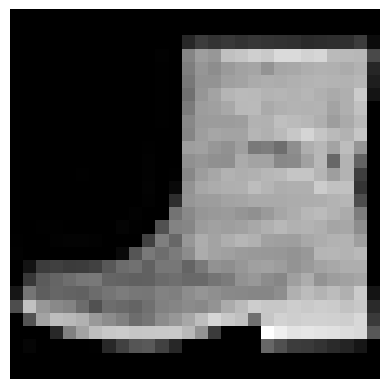

In [26]:
import matplotlib.pyplot as plt

img = X_sample.squeeze(0)
plt.imshow(img,cmap='gray')
plt.axis('off')
plt.show()

In [35]:
from torch import nn
class ImageClassifier(nn.Module):
    def __init__(self,n_inputs,n_hidden1,n_hidden2,n_classes):
        super().__init__()
        self.mlp = nn.Sequential(
            nn.Flatten(),
            nn.Linear(n_inputs,n_hidden1),nn.ReLU(),
            nn.Linear(n_hidden1,n_hidden2),nn.ReLU(),
            nn.Linear(n_hidden2,n_classes)
        )
    def forward(self,X):
        return self.mlp(X)
    
torch.manual_seed(42)
model = ImageClassifier(n_inputs=28*28,n_hidden1=300,n_hidden2=100,n_classes=10)
xentropy = nn.CrossEntropyLoss()

In [27]:
%pip install torchmetrics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.2/983.2 kB 27.8 MB/s eta 0:00:0000:01


In [28]:
import torchmetrics

accuracy = torchmetrics.Accuracy(task="multiclass",num_classes=10).to(device)

In [37]:
model.eval()


ImageClassifier(
  (mlp): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=300, bias=True)
    (2): ReLU()
    (3): Linear(in_features=300, out_features=100, bias=True)
    (4): ReLU()
    (5): Linear(in_features=100, out_features=10, bias=True)
  )
)

In [39]:
X_new,y_new = next(iter(valid_loader))


In [41]:
X_new = X_new[:3].to(device)


In [42]:
with torch.no_grad():
    y_pred_logits = model(X_new)

RuntimeError: Expected all tensors to be on the same device, but got mat1 is on cuda:0, different from other tensors on cpu (when checking argument in method wrapper_CUDA_addmm)

In [43]:
%pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 413.9/413.9 kB 15.1 MB/s eta 0:00:00


In [ ]:
import optuna
def objective(trial):
    learning_rate = trial.suggest_float("learning_rate", 1e-5,
    1e-1, log=True)
    n_hidden = trial.suggest_int("n_hidden", 20, 300)
    model = ImageClassifier(n_inputs=1 * 28 * 28,
    n_hidden1=n_hidden,
    n_hidden2=n_hidden,
    n_classes=10).to(device)
    optimizer = torch.optim.SGD(model.parameters(),
    lr=learning_rate)
    [...] # train the model, then evaluate it on the validation
    set
    return validation_accuracy

In [ ]:
torch.manual_seed(42)
sampler = optuna.samplers.TPESampler(seed=42)
study = optuna.create_study(direction="maximize",
sampler=sampler)
study.optimize(objective, n_trials=5)

In [ ]:
study.best_params

In [ ]:
study.best_value2